In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

TEMPDIR = Path(config['TEMPDIR'])

In [2]:
# counts
df = pd.read_csv(TEMPDIR / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

# Cell line differences

In [3]:
feature = 'gene'
tab = pd.read_csv(f'../results/mageck/summaries/{feature}_TP6_pooled_screen_1_counts_filtered_mageck_mle.gene_summary.txt', sep='\t', index_col=0)
tab = tab.drop('sgRNA', axis=1)
tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

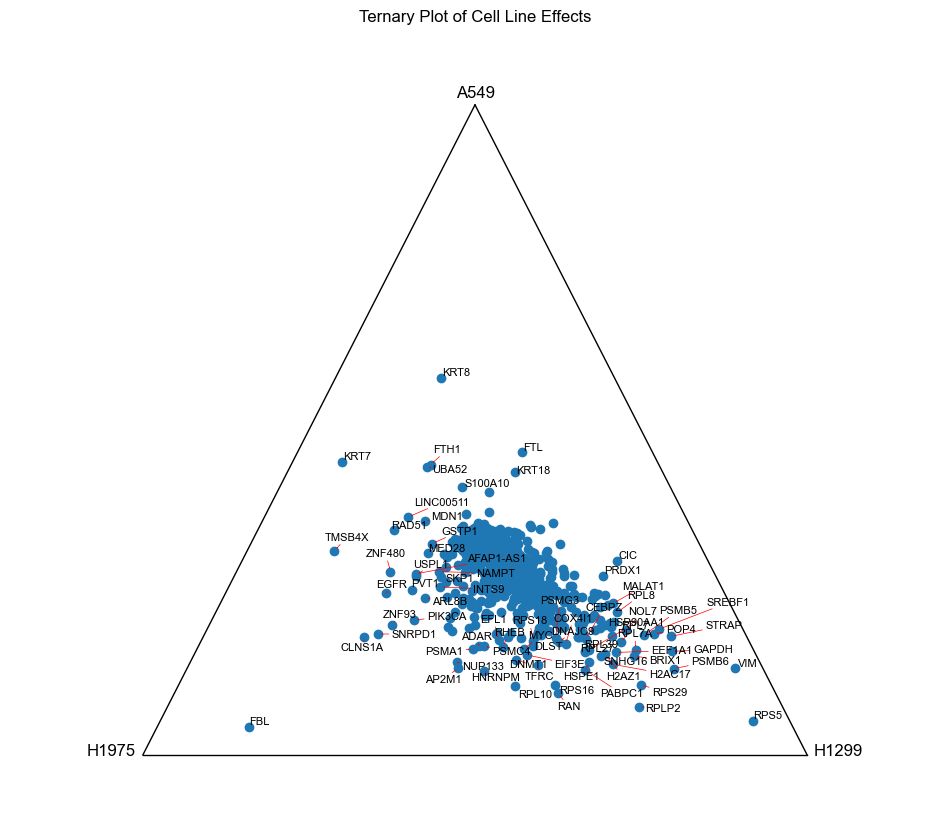

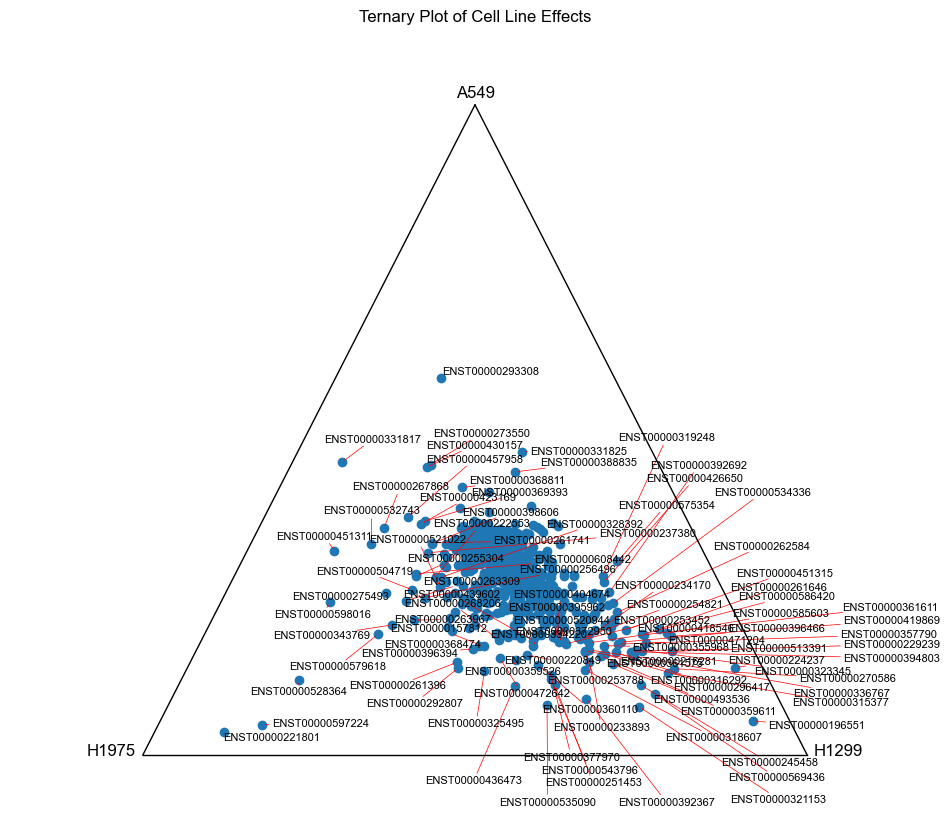

In [6]:
for feature in ['gene', 'transcript']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_TP6_pooled_screen_1_counts_filtered_mageck_mle.gene_summary.txt', sep='\t', index_col=0)
    tab = tab.drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

    # ternary plot for stab table
    # take beta values
    stab = tab.loc[:, (slice(None), 'beta')]

    from adjustText import adjust_text
    Y = -stab.values
    # apply softmax
    Y = np.exp(Y) / np.sum(np.exp(Y), axis=1)[:, None]
    Z = []
    for a,b,c in Y:
        x = 0.5 * (2*b+c)/(a+b+c)
        y = np.sqrt(3)/2 * c/(a+b+c)
        Z.append([x,y])
    Z = np.array(Z)

    # plot ternary plot
    width = 12
    fig, ax = pl.subplots(figsize=(width,width*np.sqrt(3)/2), frameon=False)

    pl.scatter(Z[:,0], Z[:,1])
    mask = (np.min(Y, axis=1) < 0.18) | (Z[:,0] < 0.45) | (Z[:,1] > 0.35)
    texts = []
    for i, txt in enumerate(stab.index):
        if mask[i]:
            texts.append(ax.annotate(txt, (Z[i,0], Z[i,1]), fontsize=8))


    # add triangle axes
    pl.plot([0, 0.5], [0, np.sqrt(3)/2], 'k-', lw=1)
    pl.plot([0.5, 1], [np.sqrt(3)/2, 0], 'k-', lw=1)
    pl.plot([0, 1], [0, 0], 'k-', lw=1)

    # add axes labels to the edges of the triangle
    pl.text(-0.01, 0, 'H1975', fontsize=12, ha='right')
    pl.text(1.01, 0, 'H1299', fontsize=12)
    pl.text(0.5, np.sqrt(3)/2+0.01, 'A549', fontsize=12, ha='center')

    # increase window size
    pl.xlim(-0.2, 1.2)
    pl.ylim(-0.1, np.sqrt(3)/2+0.1)

    pl.title('Ternary Plot of Cell Line Effects')
    adjust_text(texts, arrowprops=dict(arrowstyle="->", color='r', lw=0.5))

    # remove x and y axis but keep white background
    pl.axis('off')

    pl.savefig(f'../results/mageck/{feature}_linespecificity_ternary_plot.pdf', bbox_inches='tight')
    pl.show()

In [130]:
for feature in ['gene', 'transcript']:
    tab = pd.read_csv(f'../results/mageck/{feature}_TP6_pooled_screen_1_counts_filtered_mageck_mle.gene_summary.txt', sep='\t', index_col=0)
    tab = tab.drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

    # ternary plot for stab table
    # take beta values
    stab = tab.loc[:, (slice(None), 'beta')]
    Y = -stab.values
    spec = pd.DataFrame(np.exp(Y) / np.sum(np.exp(Y), axis=1)[:, None])
    spec.columns = stab.columns
    spec.index = stab.index
    spec.to_csv(f'../results/mageck/{feature}_linespecificity.csv')

# TP1 vs TP5/6: early responders

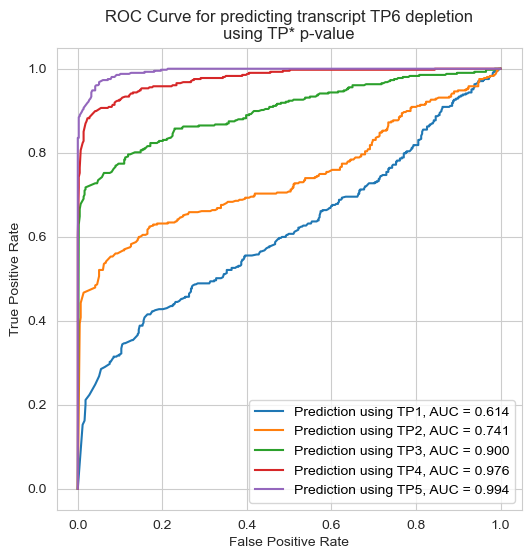

In [5]:
# Get data
feature = 'transcript'
counts = 'counts'#_filtered
tabs = {}
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

# Compare test results for TP1 and TP6 per line
# key = 'beta'
# with sns.axes_style('whitegrid'):
#     fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
# for cell_line, ax in zip(cell_line_dict.values(), axs):
#     stab = tab.loc[:, (slice(None), cell_line, slice(None))]
#     stab.columns = stab.columns.droplevel(1)
#     stab[('TP1', 'significant')] = (stab[('TP1', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
#     stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
#     stab['significant'] = ['both' if x[0] and x[1] else 'TP1' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP1', 'significant')], stab[('TP6', 'significant')])]
    
#     sns.scatterplot(data=stab, x=('TP1', key), y=('TP6', key), hue='significant', s=20, ax=ax)
#     ax.set_xlabel(f'MAGeCK {key} for TP1')
#     ax.set_ylabel(f'MAGeCK {key} for TP6')
#     # plot diagonal line using min and max values of key
#     min_ = stab.loc[:, (slice(None), key)].min().max()
#     max_ = stab.loc[:, (slice(None), key)].max().max()
#     ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
#     ax.legend(title='Significant in')
#     ax.set_title(f'MAGeCK {key} values for TP1 and TP6 in {cell_line}', fontsize=16)
# pl.show()

# ROC curve for TP6 p-value using TP1 p-value
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,6)) 
from sklearn.metrics import roc_curve, roc_auc_score
stab = tab.loc[:, (slice(None), 'H1975', slice(None))]
stab.columns = stab.columns.droplevel(1)
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5']:
    fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[(key, 'p-value')])
    auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[(key, 'p-value')])
    pl.plot(fpr, tpr, label=f'Prediction using {key}, AUC = {auc:.3f}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
pl.title(f'ROC Curve for predicting transcript TP6 depletion\nusing TP* p-value')
pl.show()

# Summarize line-wise top early responder
# An early responder is a target that is significant at TP6 and has high beta value at TP1
early_responder = {}
for cell_line in cell_line_dict.values():
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab = stab[(stab[('TP6', 'fdr')] < 0.05) & (stab[('TP6', 'beta')] < 0) & (stab[('TP1', 'beta')] < 0) & (stab[('TP1', 'fdr')]<0.05)]
    stab = stab.sort_values(('TP1', 'beta'), ascending=True)
    early_responder[cell_line] = stab.index

# Save early responder table
max_length = max([len(x) for x in early_responder.values()])
# append None to shorter lists
for cell_line in early_responder:
    early_responder[cell_line] = list(early_responder[cell_line]) + [None] * (max_length - len(early_responder[cell_line]))
# Convert this dict into a DataFrame
early_responder_df = pd.DataFrame(early_responder)
early_responder_df.to_csv(f'../results/tables/{feature}_early_responders.csv')

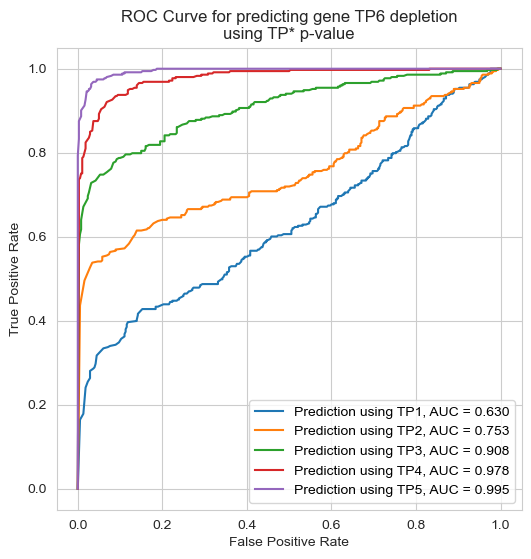

In [8]:
# Get data
feature = 'gene'
counts = 'counts'#_filtered
tabs = {}
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

# Compare test results for TP1 and TP6 per line
# key = 'beta'
# with sns.axes_style('whitegrid'):
#     fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
# for cell_line, ax in zip(cell_line_dict.values(), axs):
#     stab = tab.loc[:, (slice(None), cell_line, slice(None))]
#     stab.columns = stab.columns.droplevel(1)
#     stab[('TP1', 'significant')] = (stab[('TP1', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
#     stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
#     stab['significant'] = ['both' if x[0] and x[1] else 'TP1' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP1', 'significant')], stab[('TP6', 'significant')])]
    
#     sns.scatterplot(data=stab, x=('TP1', key), y=('TP6', key), hue='significant', s=20, ax=ax)
#     ax.set_xlabel(f'MAGeCK {key} for TP1')
#     ax.set_ylabel(f'MAGeCK {key} for TP6')
#     # plot diagonal line using min and max values of key
#     min_ = stab.loc[:, (slice(None), key)].min().max()
#     max_ = stab.loc[:, (slice(None), key)].max().max()
#     ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
#     ax.legend(title='Significant in')
#     ax.set_title(f'MAGeCK {key} values for TP1 and TP6 in {cell_line}', fontsize=16)
# pl.show()

# ROC curve for TP6 p-value using TP1 p-value
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,6)) 
from sklearn.metrics import roc_curve, roc_auc_score
stab = tab.loc[:, (slice(None), 'H1975', slice(None))]
stab.columns = stab.columns.droplevel(1)
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5']:
    fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[(key, 'p-value')])
    auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[(key, 'p-value')])
    pl.plot(fpr, tpr, label=f'Prediction using {key}, AUC = {auc:.3f}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
pl.title(f'ROC Curve for predicting {feature} TP6 depletion\nusing TP* p-value')
pl.savefig(f'../results/mageck/{feature}_ROC_curve.pdf', bbox_inches='tight')
pl.show()

# Summarize line-wise top early responder
# An early responder is a target that is significant at TP6 and has high beta value at TP1
early_responder = {}
for cell_line in cell_line_dict.values():
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab = stab[(stab[('TP6', 'fdr')] < 0.05) & (stab[('TP6', 'beta')] < 0) & (stab[('TP1', 'beta')] < 0) & (stab[('TP1', 'fdr')]<0.05)]
    stab = stab.sort_values(('TP1', 'beta'), ascending=True)
    early_responder[cell_line] = stab.index

# Save early responder table
max_length = max([len(x) for x in early_responder.values()])
# append None to shorter lists
for cell_line in early_responder:
    early_responder[cell_line] = list(early_responder[cell_line]) + [None] * (max_length - len(early_responder[cell_line]))
# Convert this dict into a DataFrame
early_responder_df = pd.DataFrame(early_responder)
early_responder_df.to_csv(f'../results/tables/{feature}_early_responders.csv')

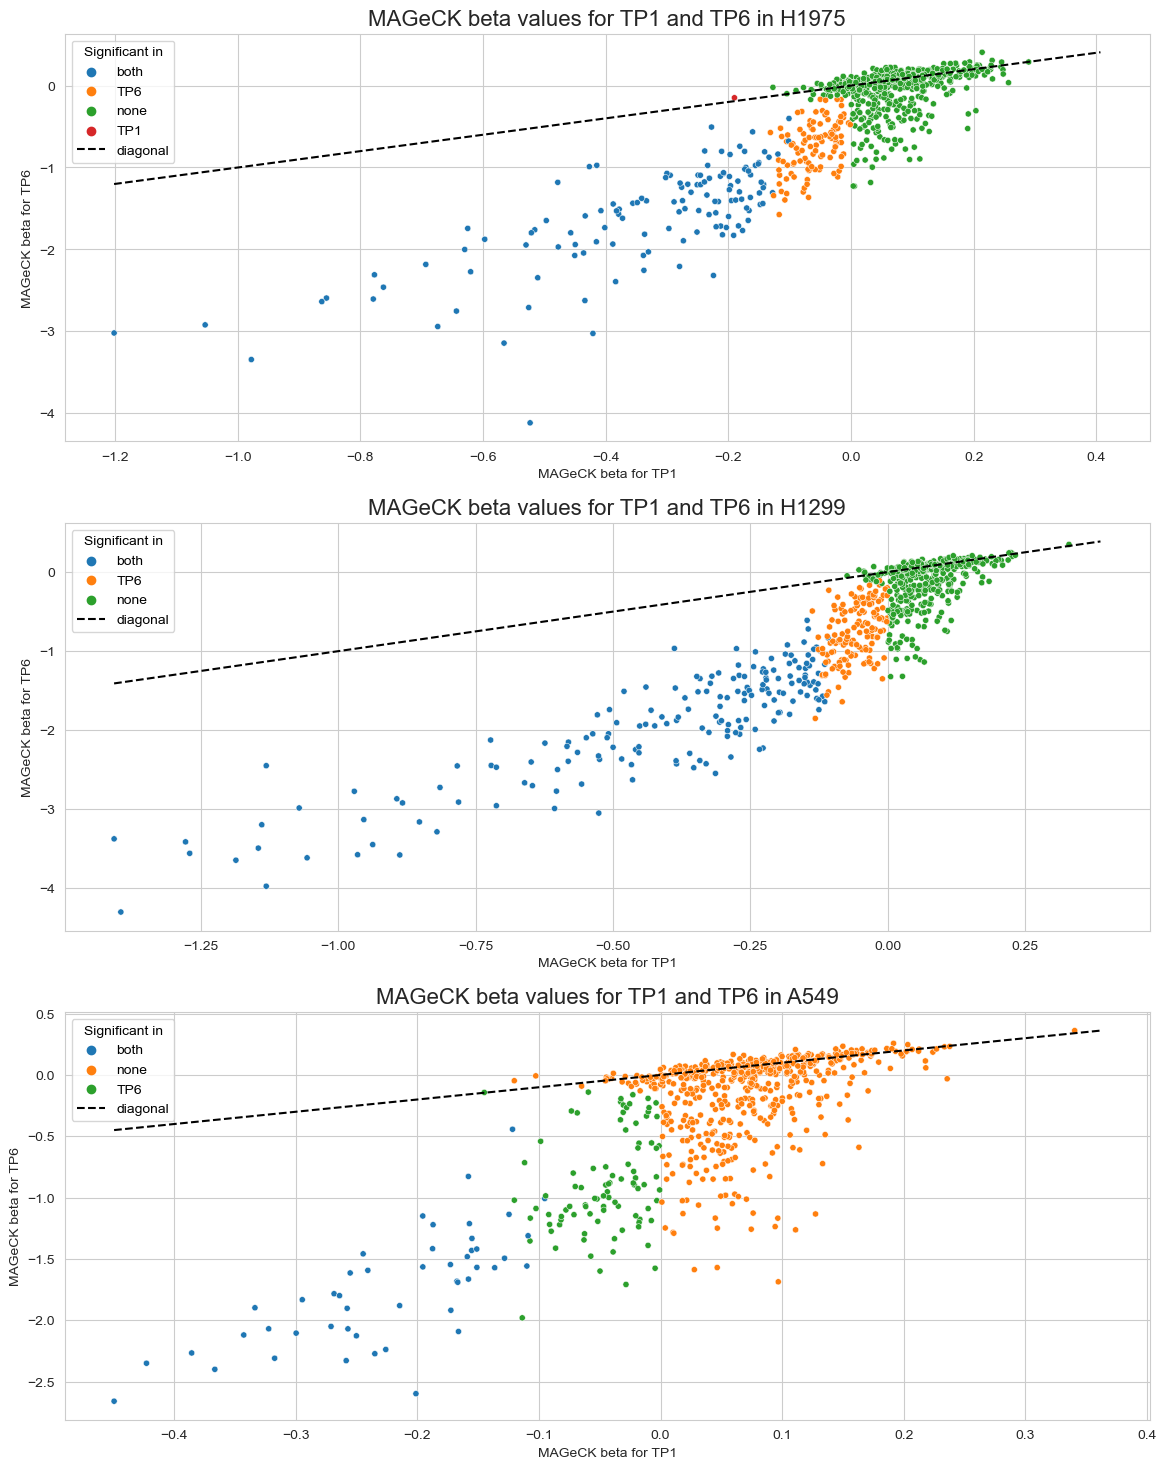

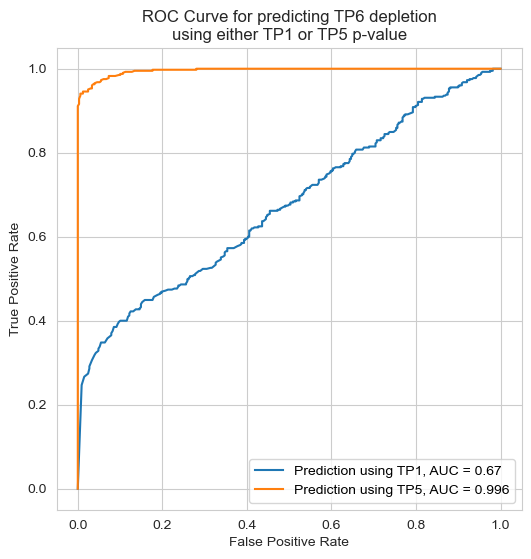

In [62]:
# Get data
feature = 'gene'
tabs = {}
for key in ['TP1', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/{feature}_{key}_pooled_screen_1_counts_filtered_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

# Compare test results for TP1 and TP6 per line
key = 'beta'
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
for cell_line, ax in zip(cell_line_dict.values(), axs):
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab[('TP1', 'significant')] = (stab[('TP1', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
    stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
    stab['significant'] = ['both' if x[0] and x[1] else 'TP1' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP1', 'significant')], stab[('TP6', 'significant')])]
    
    sns.scatterplot(data=stab, x=('TP1', key), y=('TP6', key), hue='significant', s=20, ax=ax)
    ax.set_xlabel(f'MAGeCK {key} for TP1')
    ax.set_ylabel(f'MAGeCK {key} for TP6')
    # plot diagonal line using min and max values of key
    min_ = stab.loc[:, (slice(None), key)].min().max()
    max_ = stab.loc[:, (slice(None), key)].max().max()
    ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
    ax.legend(title='Significant in')
    ax.set_title(f'MAGeCK {key} values for TP1 and TP6 in {cell_line}', fontsize=16)
pl.show()

# ROC curve for TP6 p-value using TP1 p-value
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,6)) 
from sklearn.metrics import roc_curve, roc_auc_score
stab = tab.loc[:, (slice(None), 'H1975', slice(None))]
stab.columns = stab.columns.droplevel(1)
fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[('TP1', 'p-value')])
auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[('TP1', 'p-value')])
pl.plot(fpr, tpr, label=f'Prediction using TP1, AUC = {auc:.2f}')
fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[('TP5', 'p-value')])
auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[('TP5', 'p-value')])
pl.plot(fpr, tpr, label=f'Prediction using TP5, AUC = {auc:.3f}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
pl.title(f'ROC Curve for predicting TP6 depletion\nusing either TP1 or TP5 p-value')
pl.show()

# Summarize line-wise top early responder
# An early responder is a target that is significant at TP6 and has high beta value at TP1
early_responder = {}
for cell_line in cell_line_dict.values():
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab = stab[(stab[('TP6', 'fdr')] < 0.05) & (stab[('TP6', 'beta')] < 0) & (stab[('TP1', 'beta')] < 0) & (stab[('TP1', 'fdr')]<0.05)]
    stab = stab.sort_values(('TP1', 'beta'), ascending=True)
    early_responder[cell_line] = stab.index

# Save early responder table
max_length = max([len(x) for x in early_responder.values()])
# append None to shorter lists
for cell_line in early_responder:
    early_responder[cell_line] = list(early_responder[cell_line]) + [None] * (max_length - len(early_responder[cell_line]))
# Convert this dict into a DataFrame
early_responder_df = pd.DataFrame(early_responder)
early_responder_df.to_csv(f'../results/tables/{feature}_early_responders.csv')

# TP5 vs TP6: how different? Can we pool em?

In [73]:
# Get data
feature = 'transcript'
counts = 'counts_filtered'#
tabs = {}
for key in ['TP1', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

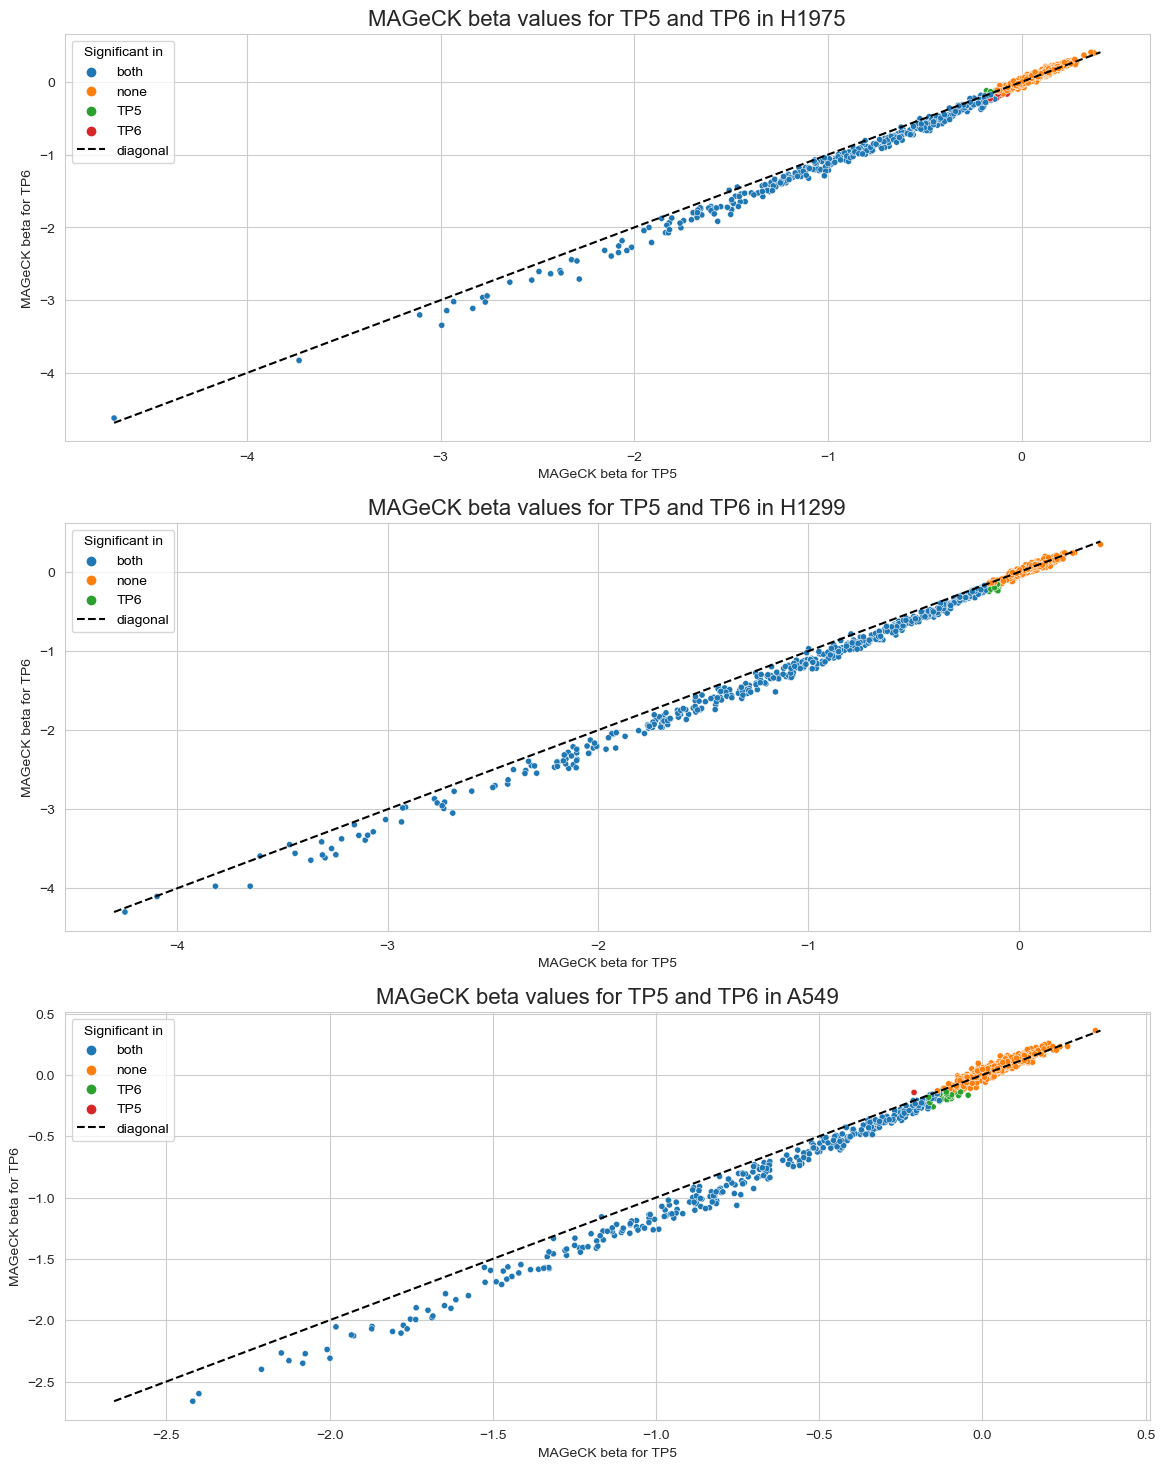

In [75]:
# Compare test results for TP1 and TP6 per line
key = 'beta'
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
for cell_line, ax in zip(cell_line_dict.values(), axs):
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab[('TP5', 'significant')] = (stab[('TP5', 'p-value')] < 0.05) & (stab[('TP5', 'beta')] < 0)
    stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP6', 'beta')] < 0)
    stab['significant'] = ['both' if x[0] and x[1] else 'TP5' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP5', 'significant')], stab[('TP6', 'significant')])]
    
    sns.scatterplot(data=stab, x=('TP5', key), y=('TP6', key), hue='significant', s=20, ax=ax)
    ax.set_xlabel(f'MAGeCK {key} for TP5')
    ax.set_ylabel(f'MAGeCK {key} for TP6')
    # plot diagonal line using min and max values of key
    min_ = stab.loc[:, (slice(None), key)].min().min()
    max_ = stab.loc[:, (slice(None), key)].max().max()
    ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
    ax.legend(title='Significant in')
    ax.set_title(f'MAGeCK {key} values for TP5 and TP6 in {cell_line}', fontsize=16)
pl.show()

# For our follow-up targets, at which TP do they stop being hits?

In [32]:
follow_ups = pd.read_excel('../resources/Selected_genes_for_follow_up.xlsx', sheet_name='Final_list ', index_col=1)
follow_ups = follow_ups.iloc[:-3]  # last 3 not in the screen
follow_up_transcripts = list(follow_ups.index.unique())

In [33]:
# Get data
feature = 'transcript'
counts = 'counts_filtered'#
tabs = {}
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

In [34]:
tab

TP1                                           \
cell_line           H1975                                            
variable             beta       z  p-value       fdr  wald-p-value   
Gene                                                                 
ENST00000436473 -0.978090 -5.6330  0.00000  0.000000  1.771200e-08   
ENST00000535090 -1.110600 -7.3521  0.00000  0.000000  1.950900e-13   
ENST00000573283 -0.620330 -4.5716  0.00000  0.000000  4.840500e-06   
ENST00000416518 -0.643540 -4.9894  0.00000  0.000000  6.055600e-07   
ENST00000286788 -0.191310 -2.0709  0.00000  0.000000  3.836900e-02   
...                   ...     ...      ...       ...           ...   
ENST00000434063  0.067929  1.5626  0.38136  0.614600  1.181600e-01   
ENST00000377726  0.142980  3.2719  0.04661  0.177420  1.068200e-03   
ENST00000231656  0.067589  1.7214  0.38347  0.614600  8.517500e-02   
ENST00000321792  0.094825  2.0650  0.23411  0.482830  3.892200e-02   
ENST00000309352  0.223030  3.1242  0.01589  0.080645  1.782800e-03   

                                                                    ...  \
cell_line                         H1299                             ...   
variable             wald-fdr      beta       z   p-value      fdr  ...   
Gene                                                                ...   
ENST00000436473  9.835600e-07 -1.056900 -6.0827  0.000000  0.00000  ...   
ENST00000535090  3.098200e-11 -1.326100 -8.7459  0.000000  0.00000  ...   
ENST00000573283  1.305500e-04 -0.953580 -7.0218  0.000000  0.00000  ...   
ENST00000416518  2.381900e-05 -0.893480 -6.9216  0.000000  0.00000  ...   
ENST00000286788  9.142100e-02 -0.269080 -2.9123  0.000000  0.00000  ...   
...                       ...       ...     ...       ...      ...  ...   
ENST00000434063  2.013400e-01  0.103100  2.3715  0.114410  0.26733  ...   
ENST00000377726  8.333800e-03  0.119720  2.7395  0.042373  0.13468  ...   
ENST00000231656  1.592200e-01  0.086088  2.1925  0.165250  0.33405  ...   
ENST00000321792  9.208700e-02  0.109600  2.3863  0.095339  0.23747  ...   
ENST00000309352  1.086300e-02  0.147850  2.0711  0.034958  0.11786  ...   

                      TP6                                                 \
cell_line           H1299                                           A549   
variable          p-value       fdr  wald-p-value      wald-fdr     beta   
Gene                                                                       
ENST00000436473  0.000000  0.000000  2.550900e-29  8.026700e-28 -2.05040   
ENST00000535090  0.000000  0.000000  3.254600e-48  5.120600e-46 -1.57870   
ENST00000573283  0.000000  0.000000  5.511500e-32  1.927000e-30 -2.12680   
ENST00000416518  0.000000  0.000000  7.286300e-28  1.965200e-26 -2.40010   
ENST00000286788  0.000000  0.000000  2.866500e-14  2.097600e-13 -1.68650   
...                   ...       ...           ...           ...      ...   
ENST00000434063  0.330510  0.419920  3.297200e-01  4.079300e-01  0.16009   
ENST00000377726  0.002119  0.004016  2.521900e-03  5.129300e-03  0.13809   
ENST00000231656  0.263770  0.349720  1.383400e-01  1.981700e-01  0.10229   
ENST00000321792  0.286020  0.373440  2.398100e-01  3.144200e-01  0.11893   
ENST00000309352  0.254240  0.340910  2.092000e-01  2.789300e-01  0.20226   

                                                                         
cell_line                                                                
variable              z   p-value       fdr  wald-p-value      wald-fdr  
Gene                                                                     
ENST00000436473 -6.6524  0.000000  0.000000  2.884100e-11  7.562800e-10  
ENST00000535090 -6.5867  0.000000  0.000000  4.496200e-11  1.116900e-09  
ENST00000573283 -8.2942  0.000000  0.000000  1.093100e-16  6.069800e-15  
ENST00000416518 -9.3815  0.000000  0.000000  6.501800e-21  1.023000e-18  
ENST00000286788 -6.2868  0.000000  0.000000  3.241600e-10  6.954700e-09  
...                 ...       ...     

In [44]:
hit_tab = tab.loc[:, (slice(None), slice(None), 'fdr')] < 0.05
hit_tab = hit_tab.loc[follow_up_transcripts]
hit_tab.columns = hit_tab.columns.droplevel(2)
hit_tab = hit_tab.swaplevel(0, 1, axis=1).sort_index(axis=1)

In [45]:
hit_tab

cell_line         A549                                     H1299         \
                   TP1    TP2    TP3    TP4    TP5    TP6    TP1    TP2   
Gene                                                                      
ENST00000355968   True   True   True   True   True   True   True   True   
ENST00000451562  False   True   True   True   True   True   True   True   
ENST00000493536  False   True   True   True   True   True   True   True   
ENST00000534336  False   True   True   True   True   True   True   True   
ENST00000539921  False   True   True   True   True   True   True   True   
ENST00000501122  False   True   True   True   True   True   True   True   
ENST00000428008  False   True   True   True   True   True   True   True   
ENST00000520944  False  False   True   True   True   True   True   True   
ENST00000521399  False   True   True   True   True   True   True   True   
ENST00000580458  False   True   True   True   True   True   True   True   
ENST00000450589  False   True   True   True   True   True   True   True   
ENST00000448718  False   True   True   True   True   True   True   True   
ENST00000418546  False  False  False   True   True   True   True   True   
ENST00000598996  False  False  False  False  False  False  False  False   
ENST00000424518  False  False  False  False  False  False  False  False   
ENST00000602385  False  False  False  False  False  False  False  False   
ENST00000521028  False  False  False  False  False  False  False  False   
ENST00000251453   True   True   True   True   True   True   True   True   
ENST00000331825  False   True   True   True   True   True  False  False   
ENST00000229239   True   True   True   True   True   True   True   True   
ENST00000359611  False   True   True   True   True   True   True   True   
ENST00000275493  False  False  False  False  False  False  False  False   
ENST00000377970   True   True   True   True   True   True   True   True   
ENST00000392367   True   True   True   True   True   True   True   True   
ENST00000430490  False  False  False  False  False  False  False  False   
ENST00000293525   True   True   True   True   True   True   True   True   
ENST00000224237  False   True   True   True   True   True   True   True   
ENST00000221801  False   True   True   True   True   True   True   True   
ENST00000597224  False   True   True   True   True   True   True   True   

cell_line                                    H1975                       \
                   TP3    TP4    TP5    TP6    TP1    TP2    TP3    TP4   
Gene                                                                      
ENST00000355968   True   True   True   True   True   True   True   True   
ENST00000451562   True   True   True   True   True   True   True   True   
ENST00000493536   True   True   True   True   True   True   True   True   
ENST00000534336   True   True   True   True   True   True   True   True   
ENST00000539921   True   True   True   True   True   True   True   True   
ENST00000501122   True   True   True   True   True   True   True   True   
ENST00000428008   True   True   True   True   True   True   True   True   
ENST00000520944   True   True   True   True  False   True   True   True   
ENST00000521399   True   True   True   True   True   True   True   True   
ENST00000580458   True   True   True   True   True   True   True   True   
ENST00000450589   True   True   True   True   True   True   True   True   
ENST00000448718   True   True   True   True   True   True   True   True   
ENST00000418546   True   True   True   True   True   True   True   True   
ENST00000598996  False  False  False  False  False  False  False  False   
ENST00000424518  False  False  False  False  False  False  False  False   
ENST00000602385  False  False  False  False  False   True   True  False   
ENST00000521028  False  False  False  False  False  False  False  False   
ENST00000251453   True   True   True   True   True   True   True   True   
ENST00000331825   True  

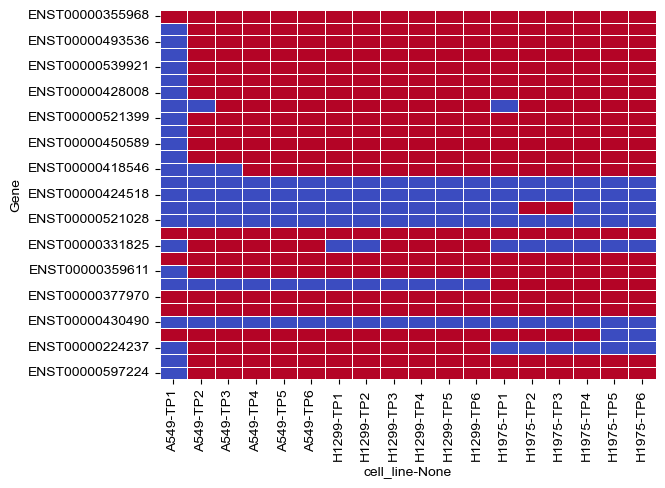

In [59]:
sns.heatmap(hit_tab, cmap='coolwarm', cbar=False, linewidths=0.5, linecolor='white')
pl.show()

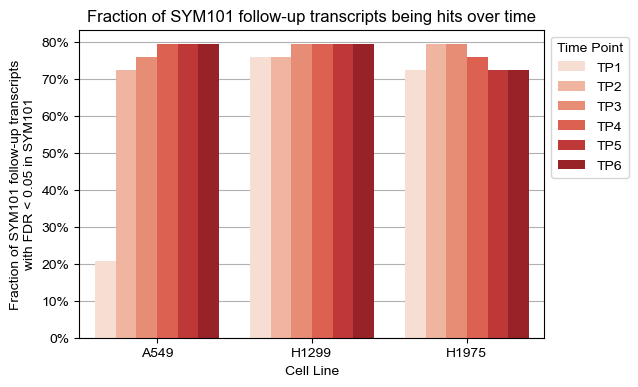

In [96]:
dat = hit_tab.sum(0).reset_index()
dat[0] = dat[0] / len(follow_up_transcripts)
dat['time_point_int'] = dat['level_1'].map({'TP1': 1, 'TP2': 2, 'TP3': 3, 'TP4': 4, 'TP5': 5, 'TP6': 6})
fig, ax = pl.subplots(figsize=(6,4))
sns.barplot(data=dat, x='cell_line', y=0, hue='level_1', palette='Reds', ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1,1), title='Time Point')
# y axis to percentage
from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel('Fraction of SYM101 follow-up transcripts\nwith FDR < 0.05 in SYM101')
ax.set_axisbelow(True)
ax.grid(axis='y')
ax.set_title('Fraction of SYM101 follow-up transcripts being hits over time')
ax.set_xlabel('Cell Line')
pl.show()